# Model-based methods · the first step

**Level** 1 · **Time** about 20 minutes

*The motivational notebook. About 20 minutes: read a little, try something, then change it and see what happens.*

## Introduction

Reinforcement learning is about learning to make decisions through rewards and penalties. You may have seen it in agents that learn to play games or robots that learn to move. 

In this notebook, we will explore how a robot can find its way through a maze. The robot is our **agent**: it chooses what to do.

The maze is its **environment**. The robot’s **state** is its current position in the maze. At each step, it chooses an **action** — moving up, down, left or right. It cannot move through walls. Each action takes it to a neighbouring cell, which becomes its new state.

We will first watch a robot that chooses its moves randomly. Then we will use the rules of the maze to help it make better decisions.


In [ ]:
#@title Poženi celico (klikni ▶ na levi, ali Shift+Enter). Kode ni potrebno brati.
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

# Barve in velikost prikaza lahko spreminjaš tukaj.
COLORS = {
    "wall": "#243f49",
    "floor": "#ffffff",
    "goal": "#b9efd5",
    "robot": "#2774d4",
    "arrow": "#203b46",
    "path": "#ca721c",
}

FIGURE_SIZE = (7, 4.5)

DIRECTIONS = {
    "up": (-1, 0),
    "right": (0, 1),
    "down": (1, 0),
    "left": (0, -1),
}

STEP_REWARD = -1 
GOAL_REWARD = 10    

def make_model(maze):
    if not maze or not maze[0] or any(len(row) != len(maze[0]) for row in maze):
        raise ValueError("The maze must be rectangular and non-empty.")
    if any(char not in "S.G#" for row in maze for char in row):
        raise ValueError("Use only S, G, # and .")

    states = [(r, c) for r, row in enumerate(maze)
              for c, char in enumerate(row) if char != "#"]
    starts = [s for s in states if maze[s[0]][s[1]] == "S"]
    goals = [s for s in states if maze[s[0]][s[1]] == "G"]
    if len(starts) != 1 or len(goals) != 1:
        raise ValueError("The maze must contain exactly one S and one G.")
    start, goal = starts[0], goals[0]
    transitions = {}
    for state in states:
        r, c = state
        transitions[state] = {
            action: (r + dr, c + dc)
            for action, (dr, dc) in DIRECTIONS.items()
            if (r + dr, c + dc) in states
        } if state != goal else {}

    return {"maze": maze, "states": states, "start": start, "goal": goal,
                "transitions": transitions}

def random_policy(model):
    # For the random policy all actions are equally likely
    return {
        state: {action: 1 / len(actions) for action in actions}
        for state, actions in model["transitions"].items()
    }

def show_maze(model, policy=None, values=None, robot=None, path=None,
              title="Robot in a maze", show=True):
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    maze = model["maze"]
    visits = Counter(path or [])

    for r, row in enumerate(maze):
        for c, char in enumerate(row):
            state = (r, c)
            color = COLORS["wall"] if char == "#" else COLORS["floor"]
            if values is not None and char != "#":
                value = values[state]
                strength = min(abs(value) / 20, 1) * 0.45
                color = (1 - strength, 1, 1 - strength) if value >= 0 else (1, 1 - strength / 2, 1 - strength)
            if state == model["goal"]:
                color = COLORS["goal"]
            if state == robot:
                color = COLORS["robot"]
            ax.add_patch(Rectangle((c - .5, r - .5), 1, 1,
                                   facecolor=color, edgecolor="#dce6e2", linewidth=1))
            if char == "#":
                continue

            text_color = "white" if state == robot else COLORS["arrow"]
            label = "START" if state == model["start"] else "GOAL" if state == model["goal"] else ""
            ax.text(c, r - .32, label, ha="center", va="center", fontsize=7, color=text_color)
            if policy is not None:
                for action, probability in policy[state].items():
                    if probability > 0:
                        dr, dc = DIRECTIONS[action]
                        ax.arrow(c, r, dc * .24, dr * .24, width=.015,
                                 head_width=.12, length_includes_head=True, color=text_color, zorder=2)
            if values is not None:
                ax.text(c, r + .32, f"{values[state]:.1f}", ha="center", va="center",
                        fontsize=8, color=text_color)
            if visits[state]:
                ax.text(c + .36, r - .30, str(visits[state]), ha="center", va="center",
                        fontsize=7, color=text_color)

    if path:
        ax.plot([s[1] for s in path], [s[0] for s in path],
                color=COLORS["path"], alpha=.45, linewidth=2)
    ax.set(xlim=(-.65, len(maze[0]) - .5), ylim=(len(maze) - .5, -.5), aspect="equal")
    ax.axis("off")
    ax.set_title(title, fontsize=12, pad=14)
    fig.tight_layout()
    if show:
        plt.show()
    return fig

def reward(model, state, action):
    next_state = model["transitions"][state][action]
    return GOAL_REWARD if next_state == model["goal"] else STEP_REWARD

def simulate_robot(model, policy, max_steps=120, seed=7):
    rng = random.Random(seed)
    state = model["start"]
    path = [state]
    total_reward = 0
    for _ in range(max_steps):
        if state == model["goal"]:
            break
        actions = list(policy[state])
        probabilities = list(policy[state].values())
        action = rng.choices(actions, weights=probabilities)[0]
        total_reward += reward(model, state, action)
        state = model["transitions"][state][action]
        path.append(state)
    return {"path": path, "steps": len(path) - 1, "reward": total_reward,
            "reached_goal": state == model["goal"]}

def run_robot(model, policy, animate=True, seed=7, max_steps=120, delay=0.06, values=None):
    result = simulate_robot(model, policy, max_steps=max_steps, seed=seed)
    if animate:
        # Posodabljamo en matplotlib prikaz. Ne uporabljamo HTML animacije.
        marker = Rectangle((model["start"][1] - .5, model["start"][0] - .5),
                           1, 1, facecolor=COLORS["robot"], alpha=.85, zorder=1.1)
        fig = show_maze(model, policy, values=values, show=False,
                        title="Robot walk · current state values" if values is not None else "Robot walk")
        fig.axes[0].add_patch(marker)
        plt.close(fig)
        handle = display(fig, display_id=True)
        for r, c in result["path"]:
            marker.set_xy((c - .5, r - .5))
            handle.update(fig)
            time.sleep(delay)
    else:
        show_maze(model, policy, values=values, robot=result["path"][-1], path=result["path"],
                  title=("Robot path · values below, visit counts at top right" if values is not None
                         else "Robot path · numbers show visit counts"))
    print("Goal reached!" if result["reached_goal"] else
          f"Goal not reached: the simulation stopped after reaching the maximum number of steps.")
    print(f"Steps: {result['steps']} | Accumulated reward: {result['reward']:g}")
    return result


>You can design your own maze by editing the grid below. Each row must have the same number of characters; the maze does not need to be square.
>Use:
>- S for the start — exactly one.
>- G for the goal — exactly one.
>- \# for walls.
>- . for open cells.
>Make sure the goal is reachable from the start.

In [59]:
MAZE =  [
        "S..#.....",
        ".#.#.#.#.",
        ".#...#...",
        ".###.#.#G",
        ".......#.",
        ]

Run the next cell to get the picture of the maze. The arrows show the actions available in each cell and the blue cell marks the robot’s position. 

>Change `seed` to generate a different walk. To show only the final plot of the path, set `animate=False`.

The display stops after 120 steps. This is a display limit, not a terminal state in our model.

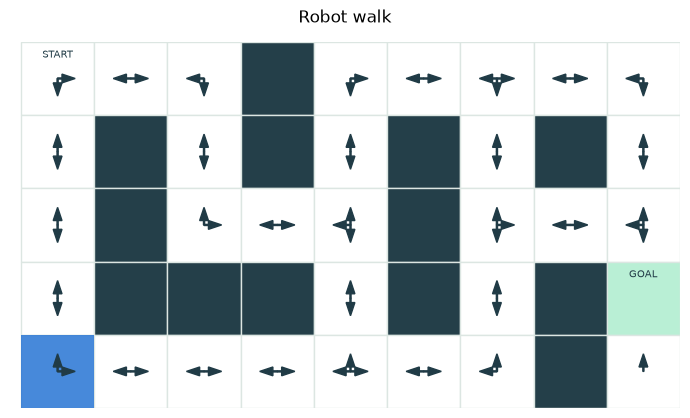

Goal not reached: the simulation stopped after reaching the maximum number of steps.
Steps: 120 | Accumulated reward: -120


In [60]:
model = make_model(MAZE)
initial_policy = random_policy(model)
random_run = run_robot(model, initial_policy, animate=True, seed=64)

As we can see, the robot’s random strategy is inefficient. It moves back and forth and revisits the same cells. It does not learn from these visits: its action probabilities stay the same, so repeating the walk does not improve its decisions.


## How can we help the robot reach the goal faster?

Let’s try to use the known rules of the maze to find better actions. To tell the robot which actions are good and bad, we introduce a reward system. Reaching the goal gives it a positive reward, `GOAL_REWARD`. Every other move gives it a small penalty, `STEP_REWARD`, encouraging it to reach the goal in fewer steps.

Most moves give the same immediate reward of −1. If the robot only considered that reward, moving towards the goal would look no better than moving away from it. To choose useful actions, we therefore need to consider both the reward for the next move and the rewards we can obtain afterwards. One move can have a small cost now but still lead us closer to the goal. 


In [45]:
STEP_REWARD = -1  
GOAL_REWARD = 10    

### Each state will be assigned a value $V^*(s)$

This describes the best future reward we can expect when starting in state $s$. Think of it as asking: “How promising is this position if the robot makes the best possible choices from here?”

Initially, all estimates are 0. These are our starting guesses. The goal’s value stays at zero because the episode ends there. The +10 reward is received when entering the goal.

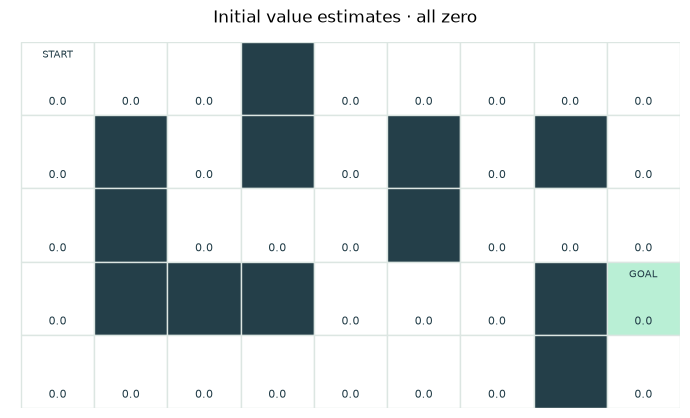

In [50]:
values = {state: 0.0 for state in model["states"]}
manual_sweeps = 0

show_maze(model, values=values, title="Initial value estimates · all zero");

Next, we look at each position and ask: “If the robot moves this way, what reward will it get now, and how promising is the position it will reach?”

We combine these two pieces of information, but give slightly less weight to what comes later. We do this by multiplying the next position’s value by 0.95. This number is called the discount factor, $\gamma$.

For a single action, the score is:

$$R(s,a)+\gamma V(s').$$
$$ \text{reward for this move} +\gamma \cdot \text{value of the next state}.$$

In [38]:

GAMMA = 0.95  

### Putting it all together: A Sweep
A **sweep** updates every state once. All updates in a sweep use the values from the previous sweep, so the result does not depend on the order in which we visit the cells.

For each non-terminal state:
1. Look at every allowed action.
2. Calculate **immediate reward + discounted value of the next state**.
3. Use the **highest** action score as the state's new value.

For example, if two actions have scores 2 and 6, the new state value is **6**. We are asking which action is best, so we take a maximum.

Mathematically:

$$V_{\mathrm{new}}(s)=\max_a\left[R(s,a)+\gamma V_{\mathrm{old}}(s')\right].$$


In [40]:
def action_value(model, values, state, action, gamma):
    """Score one action using the current estimates of future rewards."""
    next_state = model["transitions"][state][action]
    return reward(model, state, action) + gamma * values[next_state]


def value_iteration_step(model, values, gamma):
    """Update every state once, always reading from the OLD values."""
    updated_values = {}
    for state in model["states"]:
        if state == model["goal"]:
            updated_values[state] = 0.0
            continue

        action_scores = [
            action_value(model, values, state, action, gamma)
            for action in model["transitions"][state]
        ]
        updated_values[state] = max(action_scores)
    return updated_values

**Before you run the next cell:** Which cells do you expect to get positive values after the first sweep?

---

### What do you notice?

Which cells changed after the first sweep?

>Run the next cell several times. Each run performs ONE new sweep.

Completed sweeps: 6


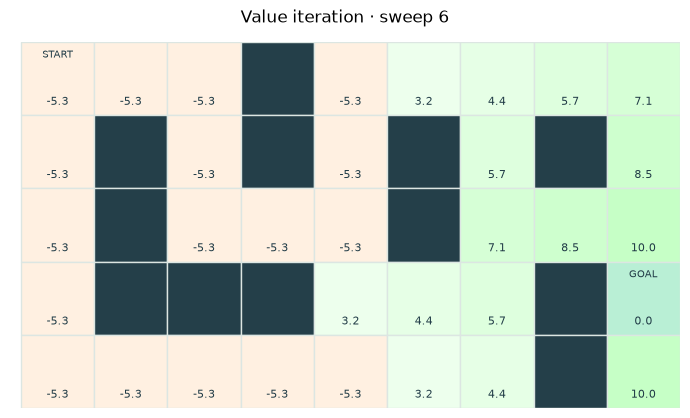

In [56]:
values = value_iteration_step(model, values, GAMMA)
manual_sweeps += 1

print(f"Completed sweeps: {manual_sweeps}")
show_maze(model, values=values, title=f"Value iteration · sweep {manual_sweeps}");

The goal's influence spreads through the maze over successive sweeps. One sweep is generally not enough to find good values everywhere.

We know the possible moves and rewards, so this is **model-based planning**. We are not learning these values from the earlier random walk.

### How will the robot choose its actions?

When sending the robot in again, we can take these values into account. Now, at each state, we will choose the action with the highest score: the immediate reward plus the discounted value of the next state. This is called a greedy policy.

In [42]:
def greedy_policy(model, values, gamma):
    """Choose one highest-scoring action at each non-terminal state."""
    policy = {}
    for state in model["states"]:
        if state == model["goal"]:
            policy[state] = {}
            continue
        scores = {
            action: action_value(model, values, state, action, gamma)
            for action in model["transitions"][state]
        }

        # best_action = max(scores, key=scores.get)
        # policy[state] = {best_action: 1.0}

        best_score = max(scores.values())

        # Find all actions tied for the highest score.
        best_actions = [
            action
            for action, score in scores.items()
            if abs(score - best_score) < 1e-8
        ]

        # Give each best action the same probability.
        policy[state] = {
            action: 1 / len(best_actions)
            for action in best_actions
        }

    return policy

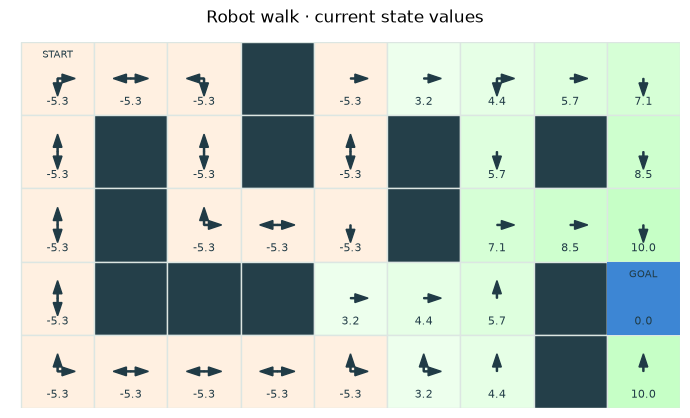

Goal reached!
Steps: 39 | Accumulated reward: -28


In [57]:
policy = greedy_policy(model, values, GAMMA)
run_robot(model, policy, animate=True, values=values);

>Run another sweep, then test the robot again. Does its route change? Repeat a few times and observe what happens.

Instead of running the sweep cell many times, we can put the updates in a loop.

### But when do we stop?

The idea is to stop once the goal’s influence has spread throughout the maze. We can recognise this when the values stop changing significantly.

After each sweep, we check the largest change in any state’s value. We stop when it falls below a small tolerance.

This process is called **value iteration**.

>The next cell finishes the remaining sweeps automatically, then sends the robot through the maze using the resulting values.


Finished after 9 additional sweeps.


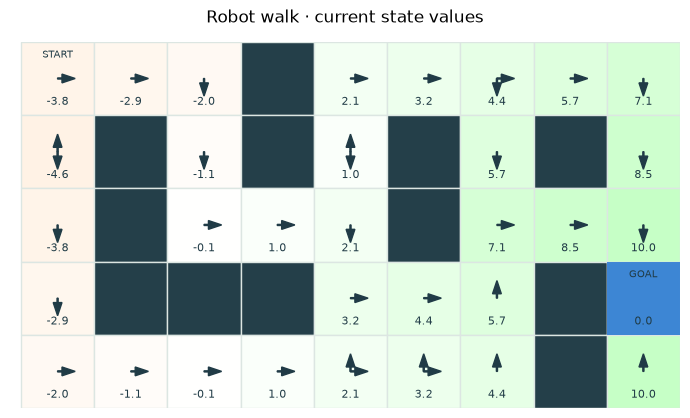

Goal reached!
Steps: 13 | Accumulated reward: -2


In [58]:
#@title Finish value iteration, then watch the robot.
tolerance = 1e-6
max_sweeps = 10000

if not 0 <= GAMMA < 1:
    raise ValueError("For this demo, use 0 <= GAMMA < 1.")

for sweep in range(1, max_sweeps + 1):
    # Calculate all new values using the previous sweep's values.
    updated_values = value_iteration_step(model, values, GAMMA)

    # How much did the most-changed state change?
    largest_change = max(
        abs(updated_values[state] - values[state])
        for state in model["states"]
    )
    values = updated_values

    if largest_change < tolerance:
        break
else:
    raise RuntimeError("Values have not settled yet. Try increasing max_sweeps.")

print(f"Finished after {sweep} additional sweeps.")

# Use the settled values to choose actions, then immediately animate the robot.
policy = greedy_policy(model, values, GAMMA)
final_run = run_robot(model, policy, animate=True, values=values)


## What was unclear

Write here what you had to look up, and what you could not solve. Then tell the person who gave you this notebook. That note makes the next version better.